In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("data.csv", encoding="latin1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (541909, 8)


In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [5]:
missing_values = df.isnull().sum()
print("Missing Values:")
print(missing_values)
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Total Missing Values: 136534


In [6]:
duplicate_count = df.duplicated().sum()
print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 5268


In [7]:
print("Cancelled Invoices:",
      df['InvoiceNo'].astype(str).str.startswith('C').sum())
print("Negative Quantities:",
      (df['Quantity'] < 0).sum())
print("Zero or Negative Quantities:",
      (df['Quantity'] <= 0).sum())
print("Zero or Negative Prices:",
      (df['UnitPrice'] <= 0).sum())
print("Missing Customer IDs:",
      df['CustomerID'].isnull().sum())

Cancelled Invoices: 9288
Negative Quantities: 10624
Zero or Negative Quantities: 10624
Zero or Negative Prices: 2517
Missing Customer IDs: 135080


In [8]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [9]:
print("Unique Customers:", df['CustomerID'].nunique())
print("Unique Products:", df['StockCode'].nunique())
print("Unique Countries:", df['Country'].nunique())
print("Total Transactions:", df['InvoiceNo'].nunique())

Unique Customers: 4372
Unique Products: 4070
Unique Countries: 38
Total Transactions: 25900


In [10]:
clean_df = df.copy()
clean_df = clean_df.drop_duplicates()
clean_df = clean_df.dropna(subset=['CustomerID'])
clean_df = clean_df[
    ~clean_df['InvoiceNo'].astype(str).str.startswith('C')
]
clean_df = clean_df[clean_df['Quantity'] > 0]
clean_df = clean_df[clean_df['UnitPrice'] > 0]
clean_df['CustomerID'] = clean_df['CustomerID'].astype(int)
print("Data cleaning completed!")
print("Original Dataset:", df.shape)
print("Cleaned Dataset:", clean_df.shape)
print("Remaining Missing Values:",
      clean_df.isnull().sum().sum())

Data cleaning completed!
Original Dataset: (541909, 8)
Cleaned Dataset: (392692, 8)
Remaining Missing Values: 0


In [11]:
clean_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom


In [12]:
clean_df['InvoiceDate'] = pd.to_datetime(
    clean_df['InvoiceDate']
)
print("InvoiceDate converted successfully!")
print(clean_df['InvoiceDate'].dtype)

InvoiceDate converted successfully!
datetime64[us]


In [13]:
clean_df['TotalAmount'] = (
    clean_df['Quantity'] * clean_df['UnitPrice']
)
print("Total purchase amount calculated!")
clean_df[['Quantity', 'UnitPrice', 'TotalAmount']].head()

Total purchase amount calculated!


,Quantity,UnitPrice,TotalAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [14]:
analysis_date = clean_df['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Analysis Date:", analysis_date)

Analysis Date: 2011-12-10 12:50:00


In [15]:
rfm = clean_df.groupby('CustomerID').agg({

    'InvoiceDate': lambda x: (
        analysis_date - x.max()
    ).days,

    'InvoiceNo': 'nunique',

    'TotalAmount': 'sum'

})
rfm.rename(columns={

    'InvoiceDate': 'Recency',

    'InvoiceNo': 'Frequency',

    'TotalAmount': 'Monetary'

}, inplace=True)
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [16]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [17]:
average_purchase_value = (
    clean_df.groupby('CustomerID')['TotalAmount'].mean()
)
rfm['AveragePurchaseValue'] = average_purchase_value
rfm[['Recency', 'Frequency', 'Monetary',
     'AveragePurchaseValue']].head()

,Recency,Frequency,Monetary,AveragePurchaseValue
CustomerID,,,,
12346,326,1,77183.60,77183.600000
12347,2,7,4310.00,23.681319
12348,75,4,1797.24,57.975484
12349,19,1,1757.55,24.076027
12350,310,1,334.40,19.670588


In [18]:
rfm['CustomerLifetimeValue'] = (
    rfm['Monetary']
)
print("Customer Lifetime Value calculated!")
rfm[['Monetary', 'CustomerLifetimeValue']].head()

Customer Lifetime Value calculated!


,Monetary,CustomerLifetimeValue
CustomerID,,
12346,77183.60,77183.60
12347,4310.00,4310.00
12348,1797.24,1797.24
12349,1757.55,1757.55
12350,334.40,334.40


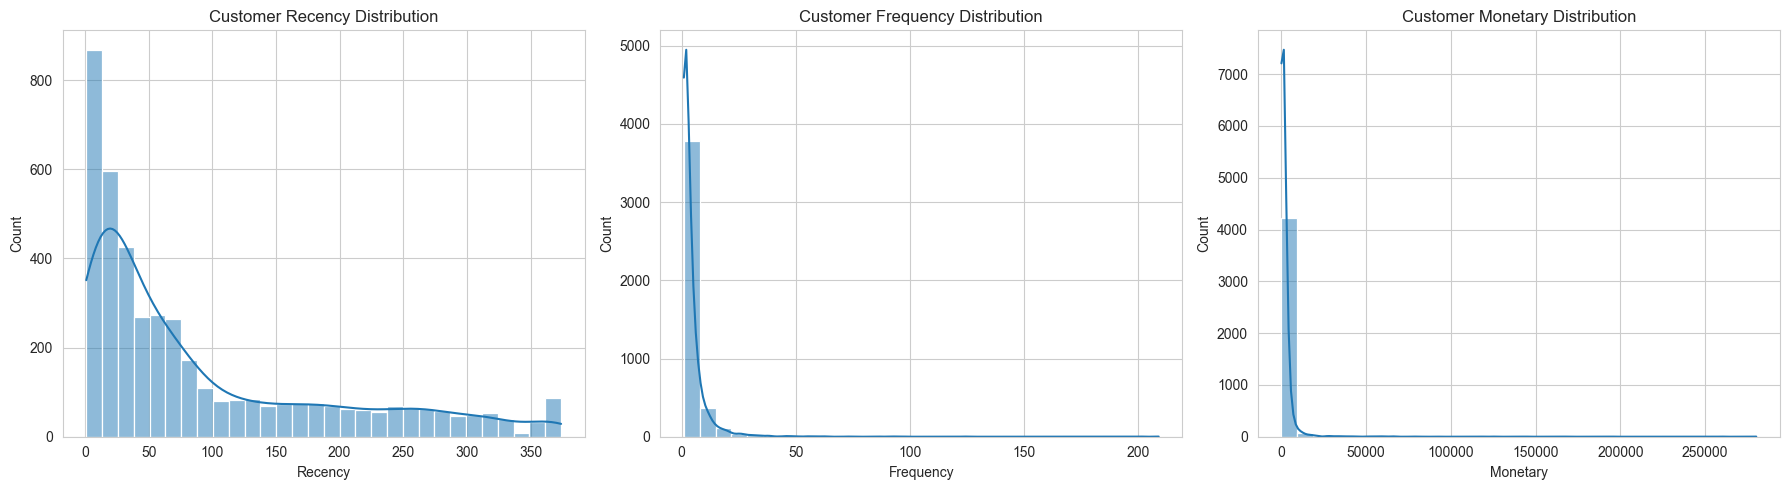

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(rfm['Recency'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Customer Recency Distribution')

sns.histplot(rfm['Frequency'], bins=30, kde=True, ax=axes[1])
axes[1].set_title('Customer Frequency Distribution')

sns.histplot(rfm['Monetary'], bins=30, kde=True, ax=axes[2])
axes[2].set_title('Customer Monetary Distribution')

plt.tight_layout()
plt.show()

In [20]:
features = rfm[['Recency', 'Frequency', 'Monetary']].copy()

print("Selected Features:")
print(features.head())
print("\nFeature Shape:", features.shape)

Selected Features:
            Recency  Frequency  Monetary
CustomerID                              
12346           326          1  77183.60
12347             2          7   4310.00
12348            75          4   1797.24
12349            19          1   1757.55
12350           310          1    334.40

Feature Shape: (4338, 3)


In [21]:
print("Missing Values:")
print(features.isnull().sum())
print("\nInfinite Values:")
print(np.isinf(features).sum())
print("\nNegative Values:")
print((features < 0).sum())

Missing Values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Infinite Values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Negative Values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


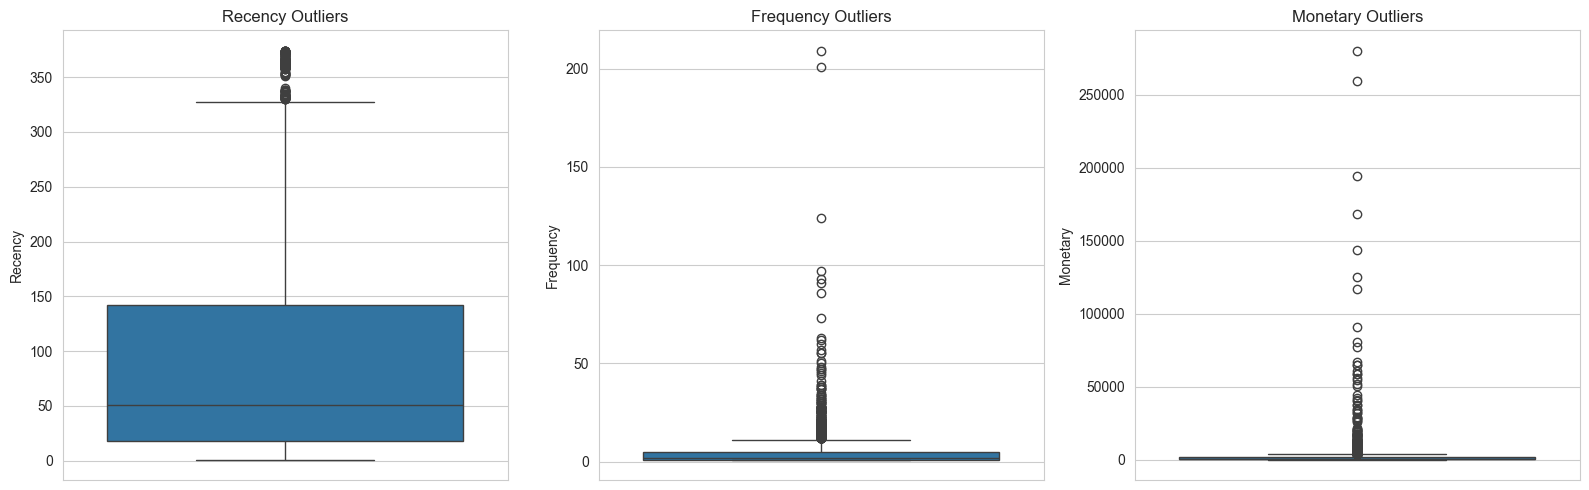

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(y=features['Recency'], ax=axes[0])
axes[0].set_title('Recency Outliers')

sns.boxplot(y=features['Frequency'], ax=axes[1])
axes[1].set_title('Frequency Outliers')

sns.boxplot(y=features['Monetary'], ax=axes[2])
axes[2].set_title('Monetary Outliers')

plt.tight_layout()
plt.show()

In [23]:
features_log = np.log1p(features)

print("Log Transformation Completed!")

features_log.head()

Log Transformation Completed!


,Recency,Frequency,Monetary
CustomerID,,,
12346,5.789960,0.693147,11.253955
12347,1.098612,2.079442,8.368925
12348,4.330733,1.609438,7.494564
12349,2.995732,0.693147,7.472245
12350,5.739793,0.693147,5.815324


In [24]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features_log)
scaled_df = pd.DataFrame(
    scaled_features,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=features.index
)
print("Standardization Completed!")
scaled_df.head()

Standardization Completed!


,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.707716
12347,-2.038734,1.074425,1.414903
12348,0.373104,0.386304,0.720024
12349,-0.623086,-0.955214,0.702287
12350,1.424558,-0.955214,-0.614514


In [25]:
print("Feature Means:")
print(scaled_df.mean())
print("\nFeature Standard Deviations:")
print(scaled_df.std())

Feature Means:
Recency     -8.025955e-17
Frequency   -8.189750e-18
Monetary    -3.669008e-16
dtype: float64

Feature Standard Deviations:
Recency      1.000115
Frequency    1.000115
Monetary     1.000115
dtype: float64


In [26]:
wcss = []
for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_df)

    wcss.append(kmeans.inertia_)
print("WCSS Values:")
print(wcss)

WCSS Values:
[13014.0, 6483.589425039296, 4869.488628540216, 3939.04938163916, 3296.7087076425432, 2855.764068043109, 2548.8202448495626, 2336.3410536103916, 2156.005672521345, 2005.7462362695576]


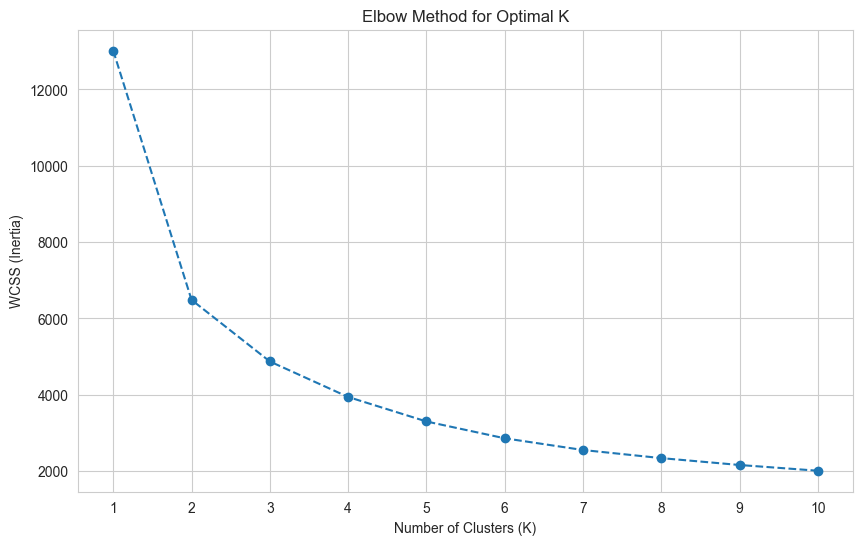

In [27]:
plt.figure(figsize=(10, 6))
plt.plot(
    range(1, 11),
    wcss,
    marker='o',
    linestyle='--'
)
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [28]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
rfm['Cluster'] = kmeans.fit_predict(scaled_df)
print("K-Means Clustering Completed!")
print("\nCustomer Cluster Labels:")
print(rfm['Cluster'].value_counts().sort_index())

K-Means Clustering Completed!

Customer Cluster Labels:
Cluster
0     769
1    1872
2    1697
Name: count, dtype: int64


In [29]:
sil_score = silhouette_score(
    scaled_df,
    rfm['Cluster']
)
print("Silhouette Score:", round(sil_score, 4))

Silhouette Score: 0.3365


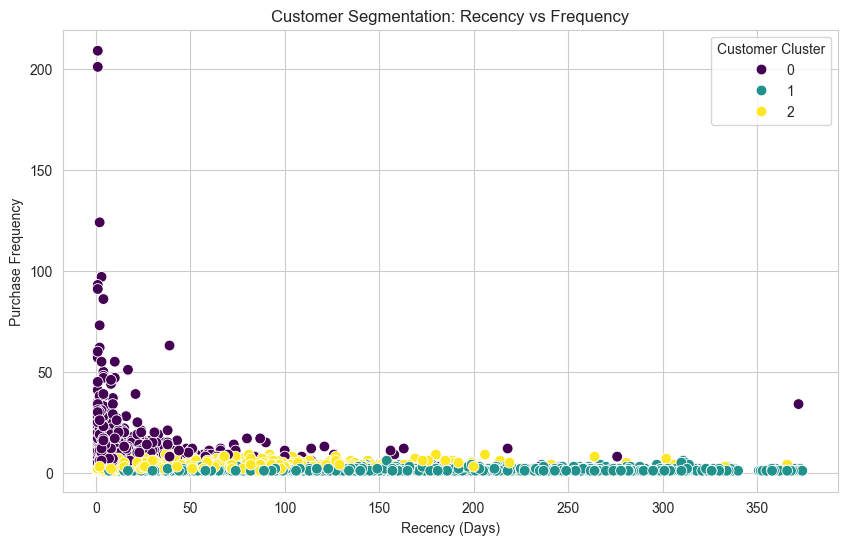

In [30]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Cluster',
    palette='viridis',
    s=60
)
plt.title('Customer Segmentation: Recency vs Frequency')
plt.xlabel('Recency (Days)')
plt.ylabel('Purchase Frequency')
plt.legend(title='Customer Cluster')
plt.show()

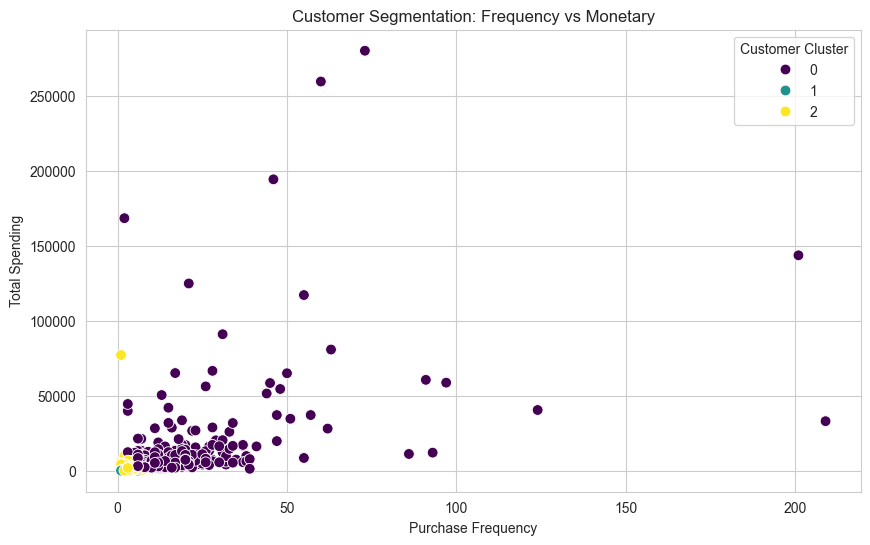

In [31]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=60
)
plt.title('Customer Segmentation: Frequency vs Monetary')
plt.xlabel('Purchase Frequency')
plt.ylabel('Total Spending')
plt.legend(title='Customer Cluster')
plt.show()

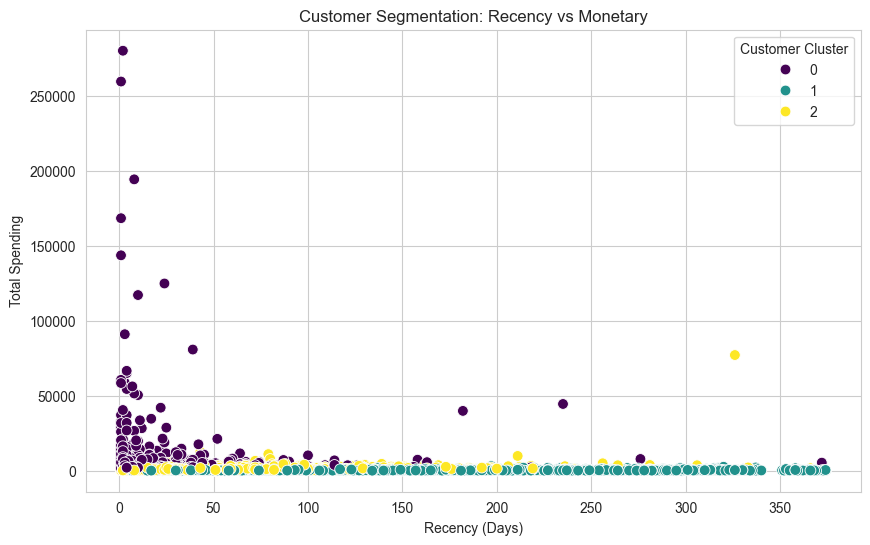

In [32]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=60
)
plt.title('Customer Segmentation: Recency vs Monetary')
plt.xlabel('Recency (Days)')
plt.ylabel('Total Spending')
plt.legend(title='Customer Cluster')
plt.show()

In [34]:
cluster_profile = rfm.groupby('Cluster').agg({

    'Recency': 'mean',

    'Frequency': 'mean',

    'Monetary': 'mean',

    'CustomerLifetimeValue': 'mean'

}).round(2)
cluster_profile['CustomerCount'] = (
    rfm.groupby('Cluster').size()
)
print("Customer Cluster Profiles:")
display(cluster_profile)

Customer Cluster Profiles:


,Recency,Frequency,Monetary,CustomerLifetimeValue,CustomerCount
Cluster,,,,,
0,17.06,13.35,7898.46,7898.46,769
1,167.36,1.35,361.00,361.00,1872
2,44.20,3.38,1259.58,1259.58,1697


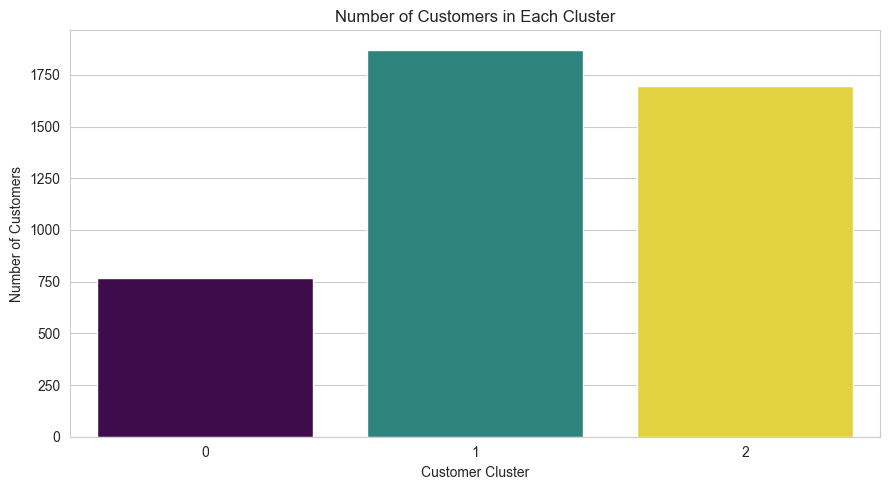

In [35]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=rfm.reset_index(),
    x='Cluster',
    hue='Cluster',
    palette='viridis',
    legend=False
)
plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

In [36]:
cluster_counts = rfm['Cluster'].value_counts().sort_index()
cluster_percentage = (
    cluster_counts / len(rfm) * 100
).round(2)
distribution = pd.DataFrame({
    'CustomerCount': cluster_counts,
    'Percentage': cluster_percentage
})
display(distribution)

,CustomerCount,Percentage
Cluster,,
0,769,17.73
1,1872,43.15
2,1697,39.12


In [37]:
display(cluster_profile)

,Recency,Frequency,Monetary,CustomerLifetimeValue,CustomerCount
Cluster,,,,,
0,17.06,13.35,7898.46,7898.46,769
1,167.36,1.35,361.00,361.00,1872
2,44.20,3.38,1259.58,1259.58,1697


# Business Insights and Marketing Recommendations

## Customer Segmentation Insights

The K-Means clustering algorithm divided customers into three distinct groups based on their purchasing behaviour.

### Marketing Recommendations

1. Champions:
   - Provide exclusive loyalty rewards.
   - Offer VIP membership.
   - Encourage referrals.

2. Regular Customers:
   - Recommend related products.
   - Provide personalized discounts.
   - Encourage repeat purchases.

3. At-Risk Customers:
   - Launch re-engagement email campaigns.
   - Offer special comeback discounts.
   - Send personalized product recommendations.

## Business Benefits

- Improved customer retention.
- Better targeted marketing campaigns.
- Increased customer lifetime value.
- Improved customer engagement.
- More effective marketing budget allocation.


In [39]:
import os
print("OS module imported successfully!")

OS module imported successfully!


In [44]:
import os
os.makedirs("images", exist_ok=True)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.savefig('images/elbow_method.png', dpi=300, bbox_inches='tight')
plt.close()
plt.figure(figsize=(9, 5))
sns.countplot(
    data=rfm.reset_index(),
    x='Cluster',
    hue='Cluster',
    palette='viridis',
    legend=False
)
plt.title('Customer Cluster Distribution')
plt.savefig('images/cluster_distribution.png', dpi=300, bbox_inches='tight')
plt.close()
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=50
)
plt.title('Customer Segmentation')
plt.savefig('images/customer_clusters.png', dpi=300, bbox_inches='tight')
plt.close()
print("All visualizations saved successfully!")
print("\nSaved Files:")
print(os.listdir("images"))

All visualizations saved successfully!

Saved Files:
['cluster_distribution.png', 'customer_clusters.png', 'elbow_method.png']
